# Notebook 19 – Complete Computer Vision Project

End-to-end project: recognize handwritten digits from document crops. Document decisions across data inspection, preprocessing, augmentation, baseline, CNN, task transfer, tuning, evaluation, error analysis, explainability, optimization, and inference.

**Learning loop:** Concept → explain in your own words → simple example → implement → interpret.

In [1]:
import io, time, copy
import numpy as np
import torch
from torch import nn
torch.manual_seed(42); np.random.seed(42)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:',torch.__version__,'| device:',device)

PyTorch: 2.14.0+cpu | device: cpu


## Problem definition and decision log
**Use case:** route a cropped handwritten digit from a scanned form to the correct numeric class. **Target:** one label, 0–9. **Success:** macro-F1 and interactive latency matter. **Limitations:** the offline demonstration uses centered 8×8 images, not real forms.

Record the user, prediction, error costs, latency budget, data provenance/license, split method, preprocessing, and acceptance threshold. The scikit-learn digits dataset keeps this workflow runnable without downloads.

split sizes: 1078 359 360 class counts: [107 109 106 110 109 109 109 107 104 108]


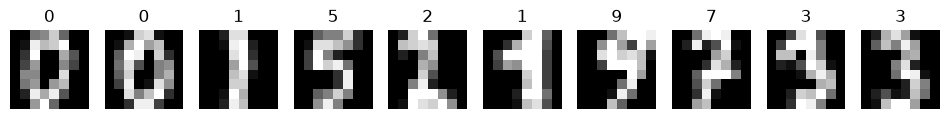

In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,precision_recall_fscore_support,confusion_matrix
from torch.utils.data import Dataset,DataLoader,TensorDataset
from torchvision import transforms
import torch.nn.functional as F
import matplotlib.pyplot as plt
d=load_digits(); images=d.images.astype(np.float32); labels=d.target.astype(np.int64)
train_idx,rest=train_test_split(np.arange(len(labels)),test_size=.4,random_state=42,stratify=labels)
val_idx,test_idx=train_test_split(rest,test_size=.5,random_state=42,stratify=labels[rest])
print('split sizes:',len(train_idx),len(val_idx),len(test_idx),'class counts:',np.bincount(labels[train_idx]))
fig,axes=plt.subplots(1,10,figsize=(12,2))
for ax,index in zip(axes,train_idx[:10]): ax.imshow(images[index],cmap='gray'); ax.set_title(str(labels[index])); ax.axis('off')
plt.show()
x=torch.tensor(images/16,dtype=torch.float32).unsqueeze(1); x=F.interpolate(x,(16,16),mode='bilinear',align_corners=False); y=torch.tensor(labels,dtype=torch.long)
class DigitDataset(Dataset):
    def __init__(self,indices,augment=False): self.indices=indices; self.augment=transforms.RandomAffine(8,translate=(.05,.05)) if augment else None
    def __len__(self): return len(self.indices)
    def __getitem__(self,i):
        index=self.indices[i]; image=x[index]
        if self.augment: image=self.augment(image)
        return image,y[index]
train_loader=DataLoader(DigitDataset(train_idx,True),batch_size=128,shuffle=True)
train_eval_loader=DataLoader(DigitDataset(train_idx),batch_size=256)
val_loader=DataLoader(DigitDataset(val_idx),batch_size=256)
test_loader=DataLoader(DigitDataset(test_idx),batch_size=256)

## Baseline, CNN, and task transfer
Random Forest is the traditional baseline. The CNN learns spatial features. For a compact transfer experiment, learn even/odd parity on training digits, reuse the convolutional encoder, then fine-tune for ten classes. This is **task transfer**, not ImageNet transfer; only training data is used for source pretraining.

In [3]:
baseline=RandomForestClassifier(n_estimators=200,random_state=42,n_jobs=-1)
start=time.perf_counter(); baseline.fit(images[train_idx].reshape(len(train_idx),-1)/16,labels[train_idx]); rf_seconds=time.perf_counter()-start
class ProjectCNN(nn.Module):
    def __init__(self,n_classes=10,dropout=.2):
        super().__init__(); self.features=nn.Sequential(nn.Conv2d(1,16,3,padding=1),nn.BatchNorm2d(16),nn.ReLU(),nn.MaxPool2d(2),nn.Conv2d(16,32,3,padding=1),nn.ReLU(),nn.AdaptiveAvgPool2d((2,2))); self.head=nn.Sequential(nn.Dropout(dropout),nn.Linear(128,n_classes))
    def forward(self,image): return self.head(self.features(image).flatten(1))
def fit(model,loader,epochs=3,lr=1e-3):
    model=model.to(device); optimizer=torch.optim.Adam(model.parameters(),lr=lr); start=time.perf_counter()
    for _ in range(epochs):
        model.train()
        for xb,yb in loader:
            xb,yb=xb.to(device),yb.to(device); optimizer.zero_grad(); loss=nn.functional.cross_entropy(model(xb),yb); loss.backward(); optimizer.step()
    return model,time.perf_counter()-start
@torch.no_grad()
def predict(model,loader):
    model.eval(); predictions=[]; truth=[]
    for xb,yb in loader: predictions.extend(model(xb.to(device)).argmax(1).cpu().tolist()); truth.extend(yb.tolist())
    return np.asarray(predictions),np.asarray(truth)
scratch,scratch_seconds=fit(ProjectCNN(),train_loader,epochs=4)
source=ProjectCNN(n_classes=2); parity_loader=DataLoader(TensorDataset(x[train_idx],y[train_idx]%2),batch_size=128,shuffle=True)
source,source_seconds=fit(source,parity_loader,epochs=3)
transfer=ProjectCNN(); transfer.features.load_state_dict(source.features.state_dict()); transfer,transfer_seconds=fit(transfer,train_loader,epochs=4,lr=5e-4)
print('training seconds: RF',round(rf_seconds,2),'scratch CNN',round(scratch_seconds,2),'source + transfer',round(source_seconds+transfer_seconds,2))

training seconds: RF 0.83 scratch CNN 3.81 source + transfer 4.4


scratch CNN held-out: {'accuracy': 0.5805555555555556, 'precision': 0.6910394035663046, 'recall': 0.580049335049335, 'macro_f1': 0.5885230416130005}
Random Forest held-out: {'accuracy': 0.9611111111111111, 'precision': 0.9627078263920369, 'recall': 0.9608644358644358, 'macro_f1': 0.9608783030003701}
common confusions (count,true,pred): [(np.int64(22), 7, 1), (np.int64(14), 8, 1), (np.int64(14), 5, 6), (np.int64(12), 9, 3), (np.int64(9), 1, 6), (np.int64(7), 4, 1), (np.int64(6), 9, 1), (np.int64(6), 2, 1)]


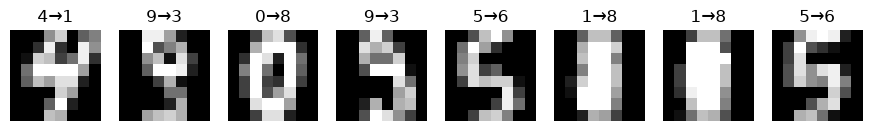

In [4]:
def macro_metrics(pred,truth):
    precision,recall,f1,_=precision_recall_fscore_support(truth,pred,average='macro',zero_division=0)
    return {'accuracy':accuracy_score(truth,pred),'precision':precision,'recall':recall,'macro_f1':f1}
scratch_val,_=predict(scratch,val_loader); transfer_val,_=predict(transfer,val_loader)
scratch_score=macro_metrics(scratch_val,labels[val_idx])['macro_f1']; transfer_score=macro_metrics(transfer_val,labels[val_idx])['macro_f1']
final_model=transfer if transfer_score>=scratch_score else scratch
final_name='task-transfer CNN' if final_model is transfer else 'scratch CNN'
test_pred,test_truth=predict(final_model,test_loader); print(final_name,'held-out:',macro_metrics(test_pred,test_truth))
rf_pred=baseline.predict(images[test_idx].reshape(len(test_idx),-1)/16); print('Random Forest held-out:',macro_metrics(rf_pred,labels[test_idx]))
cm=confusion_matrix(test_truth,test_pred); pairs=sorted([(cm[i,j],i,j) for i in range(10) for j in range(10) if i!=j],reverse=True)
print('common confusions (count,true,pred):',pairs[:8])
wrong=np.flatnonzero(test_pred!=test_truth); fig,axes=plt.subplots(1,8,figsize=(11,2))
for ax,k in zip(axes,wrong[:8]): ax.imshow(images[test_idx[k]],cmap='gray'); ax.set_title(f'{test_truth[k]}→{test_pred[k]}'); ax.axis('off')
plt.show()

## Tuning, explainability, optimization, inference
Tune on validation only. Gradient saliency is a diagnostic, not proof of causality. Select by validation macro-F1, then measure the held-out test set once. Include model size and latency in the final decision.

tuning (lr, validation macro-F1, seconds): [(0.0003, 0.06, 1.9), (0.001, 0.193, 1.9)]


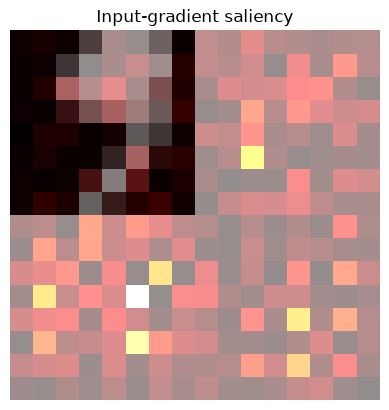

selected: scratch CNN parameters: 6122 quantized size MiB: 0.024
single image result: 9
checkpoint bytes: 28738


C:\Users\sibyr\AppData\Local\Temp\ipykernel_12132\1226632398.py:9: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  optimized=torch.ao.quantization.quantize_dynamic(copy.deepcopy(final_model).cpu(),{nn.Linear},dtype=torch.qint8)
C:\Users\sibyr\AppData\Roaming\Python\Python314\site-packages\torch\ao\nn\quantized\modules\utils.py:72: UserWarning: torch.quantize_per_tensor, to

In [5]:
# Small learning-rate sweep: same train/validation split and initialization seed.
tuning=[]
for lr in (3e-4,1e-3):
    torch.manual_seed(99); candidate,seconds=fit(ProjectCNN(),train_loader,epochs=2,lr=lr)
    pred,_=predict(candidate,val_loader); score=macro_metrics(pred,labels[val_idx])['macro_f1']; tuning.append((lr,score,seconds))
print('tuning (lr, validation macro-F1, seconds):',[(lr,round(score,3),round(seconds,2)) for lr,score,seconds in tuning])
final_model.eval(); sample=x[test_idx[0]:test_idx[0]+1].to(device).detach().requires_grad_(True); final_model.zero_grad(); chosen=final_model(sample).argmax(1).item(); final_model(sample)[0,chosen].backward(); saliency=sample.grad.abs()[0,0].detach().cpu()
plt.imshow(images[test_idx[0]],cmap='gray'); plt.imshow(saliency,cmap='hot',alpha=.45); plt.title('Input-gradient saliency'); plt.axis('off'); plt.show()
optimized=torch.ao.quantization.quantize_dynamic(copy.deepcopy(final_model).cpu(),{nn.Linear},dtype=torch.qint8)
size_buffer=io.BytesIO(); torch.save(optimized.state_dict(),size_buffer)
print('selected:',final_name,'parameters:',sum(p.numel() for p in final_model.parameters()),'quantized size MiB:',round(size_buffer.getbuffer().nbytes/1024**2,3))
def predict_digit(image_8x8):
    tensor=torch.tensor(image_8x8,dtype=torch.float32).view(1,1,8,8)/16; tensor=F.interpolate(tensor,(16,16),mode='bilinear',align_corners=False).to(device); final_model.eval()
    with torch.no_grad(): return int(final_model(tensor).argmax(1).item())
print('single image result:',predict_digit(images[test_idx[0]]))
checkpoint=io.BytesIO(); torch.save({'state_dict':final_model.cpu().state_dict(),'model_name':final_name},checkpoint); print('checkpoint bytes:',checkpoint.getbuffer().nbytes)

## Decision record and future work
Document model choice and validation evidence, held-out metrics, latency/size budget, data provenance, preprocessing and augmentation, class-specific errors, and acceptance threshold.

**Limitations:** tiny, centered images; no external forms; parity is only a teaching proxy for transfer. **Next:** collect representative licensed scans, use writer-disjoint splits, evaluate calibration/abstention, compare a genuinely pretrained domain-relevant model, and test on deployment hardware. Never report tuning scores as final test performance.